# Task 3: Comparing agreement metrics

**Task:** Compute percentage agreement (PA), Bennett's S, Cohen's κ and Gwet's AC1 on the example data and on fake data at different prevalences.

All three chance-corrected metrics compute $\frac{P_o - P_e}{1 - P_e}$ and differ only in the chance agreement $P_e$ they assume ($q_1, q_2$: share of "offensive" labels per annotator, $\bar q = (q_1 + q_2)/2$):

| Metric | Chance agreement $P_e$ | Assumption |
|---|---|---|
| Bennett's S | $0.5$ | both labels are equally likely |
| Cohen's κ | $q_1 q_2 + (1 - q_1)(1 - q_2)$ | each annotator guesses with their own prevalence |
| Gwet's AC1 | $2\bar q\,(1 - \bar q)$ | little chance agreement when one label dominates |

In [1]:
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def agreement(a, b):
    """PA and chance-corrected agreement for two annotators' labels (boolean arrays, True = offensive)."""
    p_o = np.mean(a == b)
    q1, q2 = a.mean(), b.mean()
    q = (q1 + q2) / 2
    p_e = {"Bennett's S": 0.5, "Cohen's κ": q1 * q2 + (1 - q1) * (1 - q2), "Gwet's AC1": 2 * q * (1 - q)}
    return {"PA": p_o} | {metric: (p_o - e) / (1 - e) for metric, e in p_e.items()}

## 1. Example data

Labels of anna and max before and after discussion (texts that were not discussed keep their first label). Task 1 found no missing labels.

In [2]:
df = pd.concat([pd.read_json(f, lines=True) for f in sorted(glob("example_data/*.jsonl"))], ignore_index=True)


def offensive(row, user, stage):
    """True if `user` labeled the text offensive (Arbiter stores "not offensive" as an empty label list)."""
    entries = row.labels_discussion if stage == "after" and row.labels_discussion else row.labels_annotation
    return any(e["labels"] for e in entries if e["user"] == user)


for stage in ["before", "after"]:
    for user in ["anna", "max"]:
        df[f"{stage}_{user}"] = df.apply(offensive, axis=1, user=user, stage=stage)

subsets = {f"all (N={len(df)})": df} | {f"batch {b} (N={len(g)})": g for b, g in df.groupby("batch_number")}
example = pd.DataFrame({
    (name, stage): agreement(sub[f"{stage}_anna"].to_numpy(), sub[f"{stage}_max"].to_numpy())
    for name, sub in subsets.items() for stage in ["before", "after"]
}).T.rename_axis(["data", "discussion"])
example.round(3)

PA  Bennett's S  Cohen's κ  Gwet's AC1
data            discussion                                           
all (N=81)      before      0.914        0.827      0.721       0.875
                after       0.975        0.951      0.922       0.964
batch 14 (N=30) before      0.833        0.667      0.516       0.748
                after       0.933        0.867      0.792       0.902
batch 43 (N=51) before      0.961        0.922      0.865       0.945
                after       1.000        1.000      1.000       1.000

## 2. Fake data

Same simulation as in Task 2: **guessing annotators** (no real agreement) vs. **95 % accurate annotators** (same real agreement at every prevalence).

In [3]:
rng = np.random.default_rng(42)
N = 10_000  # large N, so the curves show expected values instead of sampling noise
prevalences = np.linspace(0.05, 0.95, 19).round(2)
scenarios = {"guessing annotators": None, "95 % accurate annotators": 0.95}


def fake_labels(p, accuracy=None):
    """Labels of two annotators for N texts (True = offensive) at prevalence p.
    accuracy=None: both guess; otherwise both copy the true label and err with probability 1 - accuracy."""
    if accuracy is None:
        return rng.random(N) < p, rng.random(N) < p
    truth = rng.random(N) < p
    return truth ^ (rng.random(N) > accuracy), truth ^ (rng.random(N) > accuracy)


fake = {name: pd.DataFrame([agreement(*fake_labels(p, acc)) for p in prevalences], index=prevalences)
        for name, acc in scenarios.items()}
pd.concat({name: d.loc[[0.05, 0.2, 0.5]] for name, d in fake.items()}, names=["scenario", "prevalence"]).round(2)

PA  Bennett's S  Cohen's κ  Gwet's AC1
scenario                 prevalence                                          
guessing annotators      0.05        0.91         0.81      -0.01        0.90
                         0.20        0.69         0.37       0.00        0.54
                         0.50        0.51         0.01       0.01        0.01
95 % accurate annotators 0.05        0.91         0.81       0.45        0.89
                         0.20        0.90         0.81       0.73        0.85
                         0.50        0.91         0.82       0.82        0.82

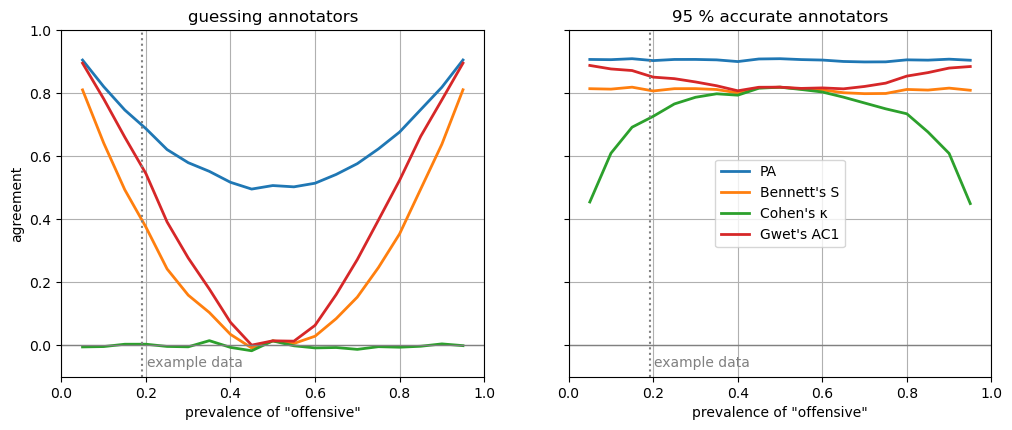

In [4]:
example_prevalence = df[["before_anna", "before_max"]].to_numpy().mean()  # share of "offensive" labels (0.19)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, d) in zip(axes, fake.items()):
    d.plot(ax=ax, lw=2, title=name, xlim=(0, 1), ylim=(-0.1, 1), grid=True, legend=False)
    ax.axhline(0, color="gray", lw=1)
    ax.axvline(example_prevalence, color="gray", ls=":")
    ax.text(example_prevalence + 0.01, -0.07, "example data", color="gray")
    ax.set_xlabel('prevalence of "offensive"')
axes[0].set_ylabel("agreement")
axes[1].legend()
plt.show()

## Results

**Example data** (before discussion): PA 0.91 > AC1 0.87 > S 0.83 > κ 0.72. With ≈ 19 % offensive labels the metrics assume very different chance agreement (κ: 0.69, S: 0.50, AC1: 0.31). The more chance a metric assumes, the lower its value. The gap is largest in batch 14 (κ 0.52 vs. AC1 0.75).

**Fake data:**
- At 50 % prevalence S, κ and AC1 are equal. They only diverge when the prevalence is skewed, as for offensive language.
- **Guessing annotators:** only κ stays at 0. S and AC1 rise with skewed prevalence. At 5 % offensive, pure guessing reaches S = 0.81 and AC1 = 0.90, as high as for 95 % accurate annotators.
- **95 % accurate annotators:** S (0.81) and AC1 (0.81–0.89) stay stable, but κ drops from 0.81 to 0.45 at 5 % offensive, although the annotators are equally good (*kappa paradox*).

**Which metric would we choose?** Every metric encodes its own model of chance, so none is neutral. For our skewed data we would report **Cohen's κ**: it is the only metric that gives 0 for guessing, and at ≈ 20 % offensive it separates guessing (0.00) from 95 % accurate annotators (0.73) most clearly (S: 0.37 vs. 0.81, AC1: 0.54 vs. 0.85). Because κ depends on the prevalence, we always report it together with PA, the prevalence and the 2×2 matrix.